# Lecture 12 notebook: the tape

This notebook replays Lecture 12 for any USD-M perpetual on Binance and any period: it downloads the aggregated trades, checks them,
finds and patches holes, builds the derived tables, and then explores and describes the data. Everything runs on an ordinary computer:
the pipeline works one month, and within a month one day, at a time.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings: market, period, data folder; what to expect in time and memory | Appendix A.2 |
| 1 | The pipeline: download and check, find holes, patch, clean, aggregate, sequence | §4, §5 |
| 2 | Data quality: at a glance, by month, flag register, holes and patches, candles against Binance's | §5, §8.1 |
| 3 | Explorer: activity and coverage, list of events, day view, density, raw rows, extreme events | §5 |
| 4 | The market's activity: trade sizes, aggressor, time of day, durations, funding | §6 |
| 5 | How prices form: persistence, signature plot, large moves | §7 |
| 6 | What a candle loses: same candle, flow, volatility, close against VWAP, volume by price | §8 |

The pipeline code is in `tape.py`, the data-quality tables in `l12_stats.py`, and the code behind the lecture's figures in `l12_figures.py`, next to this notebook. Data are written to `data/` at the top of the repository, which git ignores:
nothing downloaded is ever committed. To keep data elsewhere, set the environment variable `TAPE_ROOT` before starting Jupyter.

## 0. Settings

Choose the market and the period (months, `YYYY-MM`). The default, August and September 2022, contains the archive's holes of §5.2:
four missing days in August and September, a day missing on 10 September, two duplicated days, and the six minutes missing from the archive on 6 September.

In [1]:
import os, sys, time
os.environ.setdefault("POLARS_MAX_THREADS", "4")      # fewer threads: lower peak memory, longer run
import polars as pl, psutil
import tape

SYMBOL = "BTCUSDT"     # any USD-M perpetual, e.g. "ETHUSDT"
START = "2022-08"      # first month
END = "2022-09"        # last month

pl.Config.set_tbl_rows(30); pl.Config.set_fmt_str_lengths(60)
print("data folder:", tape.ROOT)
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB; "
      f"each stage waits until {tape.MIN_FREE_GB} GB are free")

data folder: …/systematic-trading-notes/data
free memory: 2.1 GB of 16.9 GB; each stage waits until 2.5 GB are free


**What to expect.** Measured on a computer with 16 GB of memory and four threads (Appendix A.2), per month:

| Stage | Peak memory | Time per month |
|---|---|---|
| Get: download, convert, check | about 2.3 GB | 1–2 minutes, mostly downloading |
| Find holes, patch, clean | about 3.2 GB | a few minutes for the whole period |
| Aggregate | 1.9–3.1 GB | 5 to 15 seconds |
| Sequence | 1.6–3.2 GB | 30 seconds to 2 minutes; longer in busy months |

A month of BTCUSDT takes about 0.4 GB of disk as Parquet. Months already downloaded are not downloaded again,
so the cell below can be rerun after an interruption.

## 1. The pipeline

`tape.run_pipeline` runs the six stages of §4.3, each stage and month in a fresh process, so that its memory is freed and its peak measured:

1. **get**: download the monthly zip, verify its checksum, convert to Parquet, check rows, IDs and time order, log, delete the zip;
2. **find holes**: every jump and every repeat in the trade IDs, across month boundaries;
3. **patch**: for each missing range, download the daily files of the days it spans, and check that they fill it exactly;
4. **clean**: for months with holes or repeats only, write raw + patches − duplicates;
5. **aggregate**: counts, volumes, histograms and quantiles, with Polars' streaming engine;
6. **sequence**: day by day, with the last trades of each day carried into the next: bars, realised variance, durations, persistence, flags.

In [2]:
t0 = time.time()
holes, patches, log = tape.run_pipeline(SYMBOL, START, END)
print(f"done in {(time.time() - t0) / 60:.1f} minutes")

get 2022-08: done


get 2022-09: done


holes: 5 ranges of missing IDs, 2 days with repeated IDs


aggregate and sequence 2022-08: done


aggregate and sequence 2022-09: done


done in 0.1 minutes


**Time and peak memory**, per stage and month: `waited_s` is the time spent waiting for free memory, `run_s` the work itself; months already downloaded or already processed are not done again (set `rebuild=True` to redo them).

In [3]:
log

month,stage,done,waited_s,run_s,peak_gb
str,str,str,f64,f64,f64
"""2022-08""","""get""","""already there""",0.0,0.7,null
"""2022-09""","""get""","""already there""",0.0,0.7,null
"""2022-08""","""aggregate""","""already there""",0.0,0.0,null
"""2022-08""","""sequence""","""already there""",0.0,0.0,null
"""2022-09""","""aggregate""","""already there""",0.0,0.0,null
"""2022-09""","""sequence""","""already there""",0.0,0.0,null


## 2. Data quality

How complete and how clean the data are, before anything is analysed (§5 of the lecture). Nothing is ever deleted: unusual prints stay
in the data with a flag, so every figure below describes exactly what the analyses use.

In [4]:
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import plotly.graph_objects as go
from IPython.display import Image, display
from trading_models.plotting import INK, MUTED, SERIES, apply_theme, save_figure

apply_theme(); FIG = Path("figures").resolve()
D = tape.ROOT / "interim" / "tape" / SYMBOL
period = tape.months(START, END)
pl.Config.set_tbl_hide_dataframe_shape(True)
def ms(text):
    """'YYYY-MM-DD HH:MM[:SS[.fff]]' in UTC -> milliseconds since 1970."""
    return int(datetime.fromisoformat(text).replace(tzinfo=timezone.utc).timestamp() * 1000)

def show(fig, name):
    """Save a chart under figures/ and display it as an image (an image also shows on GitHub)."""
    save_figure(fig, name, FIG); display(Image(filename=str(FIG / f"{name}.png")))

import l12_stats as l12

### 2.1 At a glance

The default period is the worst of the five years, chosen to show the repairs. Over the five years from October 2021,
99.9988% of the trades Binance recorded are in the data.

In [5]:
l12.quality_report(SYMBOL, START, END, holes, patches)

BTCUSDT, 2022-08 to 2022-09: 99.9636% of the trades Binance recorded are in the data; nothing was deleted.


measure,count,share
str,str,str
"""Trades in the period, after patching""","""86,896,965""","""100%"""
"""Missing from the monthly files""","""6,465,602""","""7.4378%"""
""" filled exactly from the daily files""","""6,433,946""","""7.4014%"""
""" missing from the whole archive, recorded""","""31,656""","""0.0364%"""
"""Duplicated rows, kept once""","""4,316,651""","""4.9676%"""
"""Days complete""","""60 of 61""","""98.4%"""
"""Time with no trade for over a minute""","""6.4 minutes""","""0.0072% of the time"""
"""Unusual prints, flagged and kept""","""369""","""0.0004%"""
"""Prices off the tick grid, kept""","""637""","""0.0007%"""


### 2.2 Month by month

The same measures for each month, in percent of the month's trades: how much was missing from the monthly files, how much remains
missing after patching, duplicated rows, minutes without any trade, unusual prints, and prices off the tick grid.

In [6]:
l12.quality_by_month(SYMBOL, period, holes, patches)

month,trades,missing_pct,unfilled_pct,duplicated_pct,no_trade_minutes,unusual_prints,off_grid_pct,complete_pct
str,i64,f64,f64,f64,f64,i64,f64,f64
"""2022-08""",44534075,8.9315,0.0,0.0,0.0,51,0.0008,100.0
"""2022-09""",42362890,5.8688,0.0747,10.1897,6.4,318,0.0007,99.9253


### 2.3 The flag register

Every rule of §5.3, how often it fired, on how many days, and as a share of all trades. *Error*: the data are wrong or missing;
*check*: worth a look; *event*: a real market event.

In [7]:
l12.flag_register(SYMBOL, period)

rule,kind,count,days,share_of_trades_pct
str,str,i64,i64,f64
"""fills not in the aggregated tape""","""check""",28463,61,0.03275
"""spike and revert""","""check""",95,9,0.00011
"""silence over 60 seconds""","""check""",1,1,0.0
"""missing trades""","""error""",2,1,0.0
"""quantity off the lot step""","""error""",0,0,0.0
"""price off the tick grid""","""event""",637,59,0.00073
"""very large trade (over $5 million)""","""event""",379,61,0.00044
"""jump that persists""","""event""",274,11,0.00032
"""activity burst (20 times the day's median minute)""","""event""",54,23,0.00006


### 2.4 Holes and patches

Each hole: the trade IDs that jump (missing trades) or repeat (duplicated rows), with the times of the trades on either side, and for
missing ranges the verdict of the patch: "filled" closes the hole exactly; "not in the archive" means Binance's daily files miss the same trades.

In [8]:
def show_holes(h):
    return h.with_columns(pl.from_epoch("from_ms", time_unit="ms").alias("from"), pl.from_epoch("to_ms", time_unit="ms").alias("to"),
                          ((pl.col("to_ms") - pl.col("from_ms")) / 60_000).round(1).alias("minutes")).select("kind", "month", "n", "from", "to", "minutes")

show_holes(holes).join(patches.select("from_ms", "patched", "status"), left_on=pl.col("from").dt.epoch("ms"), right_on="from_ms", how="left").drop("from_ms", strict=False)     if patches.height else show_holes(holes)

kind,month,n,from,to,minutes,patched,status
str,str,i64,datetime[μs],datetime[μs],f64,i64,str
"""missing""","""2022-08""",3977571,2022-08-27 23:59:59.923,2022-08-31 00:00:00.081,4320.0,3977571,"""filled"""
"""missing""","""2022-09""",1377907,2022-08-31 23:59:59.930,2022-09-02 00:00:00.038,1440.0,1377907,"""filled"""
"""missing""","""2022-09""",31645,2022-09-06 17:14:36.603,2022-09-06 17:20:57.627,6.4,0,"""not in the archive"""
"""missing""","""2022-09""",11,2022-09-06 17:58:09.820,2022-09-06 17:58:10.719,0.0,0,"""not in the archive"""
"""missing""","""2022-09""",1078468,2022-09-09 23:59:59.889,2022-09-11 00:00:00.107,1440.0,1078468,"""filled"""
"""repeated""","""2022-09""",1751914,2022-09-12 00:00:00,2022-09-13 00:00:00,1440.0,null,null
"""repeated""","""2022-09""",2564737,2022-09-13 00:00:00,2022-09-14 00:00:00,1440.0,null,null


### 2.5 Our candles against Binance's

Binance publishes its own one-minute candles. Candles rebuilt from the tape should match them; where they do not, §8.1 of the lecture
explains why: rows straddling a minute's start, minutes missing from the archive's tape, and minutes missing from Binance's candle file.
The candles are downloaded once (a few MB per month).

In [9]:
l12.candles_vs_binance(SYMBOL, period)

part,value,note
str,str,str
"""minutes compared""","""87,835""",""""""
"""close identical""","""100.00%""",""""""
"""high and low identical""","""99.49%""","""the rest: rows straddling a minute's start"""
"""open identical""","""89.35%""","""where not, Binance's open is the previous close in 100.0% of…"
"""volume identical""","""72.3%""","""the rest typically differ by one part in a million"""
"""Binance trades per aggregated trade""","""2.94""","""Binance counts single fills"""
"""minutes Binance shows without trades, the tape has trades""","""0""","""0 trades on the tape"""
"""minutes Binance has, the tape does not""","""5""","""trades missing from the archive's tape"""


## 3. Explorer: where the data are, and where they are not

Five views for looking at the data themselves:

| View | What it shows |
|---|---|
| 3.1 Coverage map | Trades and dollars per day, with patched holes, holes left unfilled, duplicated days and outages marked |
| 3.2 What to look at | The same events as a list, with times |
| 3.3 Day view | Every trade of a day or a window, coloured by the aggressor's side, with flagged prints and holes marked |
| 3.4 Density | All trades of a span, from hours to weeks, as one image of price against time, shaded by the dollars traded |
| 3.5 Raw rows | The exact rows around one moment |

The settings below choose what the views show. The defaults point at 6 September 2022: the six minutes missing from the archive and,
two minutes before, the isolated print at $28,368 (§5.4). With `INTERACTIVE = True`, the day view becomes a zoomable chart
(plotly-resampler: it draws only what the screen can show and fetches more detail as you zoom, down to single trades).

In [10]:
# ---- CHANGE HERE: what the explorer shows -------------------------------------------------------------
DAY = "2022-09-06"                       # day view: the archive gap (17:14-17:20 UTC) and the isolated print at 17:12:26
WINDOW = ("17:00", "17:30")              # zoom of the day view, UTC; None for the whole day
DENSITY = ("2022-09-21 12:00", "2022-09-22 00:00")   # density image: any span, UTC; the Fed decision at 18:00. A day or less shows most detail
ROWS_AT = "2022-09-06 17:12:26.397"      # raw rows around this moment, UTC, to the millisecond
INTERACTIVE = False                      # True: zoomable day view in a running notebook; False: static images
# --------------------------------------------------------------------------------------------------------
if DAY[:7] not in period:
    DAY, WINDOW = f"{period[0]}-01", None; print(f"DAY is outside the period: showing {DAY} instead")
if DENSITY[0][:7] not in period or DENSITY[1][:7] not in period + [tape.months(END, "9999-12")[1]]:
    DENSITY = (f"{period[0]}-01 00:00", f"{period[0]}-02 00:00"); print(f"DENSITY is outside the period: showing {DENSITY} instead")
if ROWS_AT[:7] not in period:
    ROWS_AT = f"{period[0]}-01 12:00:00.000"; print(f"ROWS_AT is outside the period: showing {ROWS_AT} instead")

### 3.1 Coverage map

Trades and dollars per day, as in figure 12_01 of the lecture, with a mark on every day where the inspection of §5 found something.

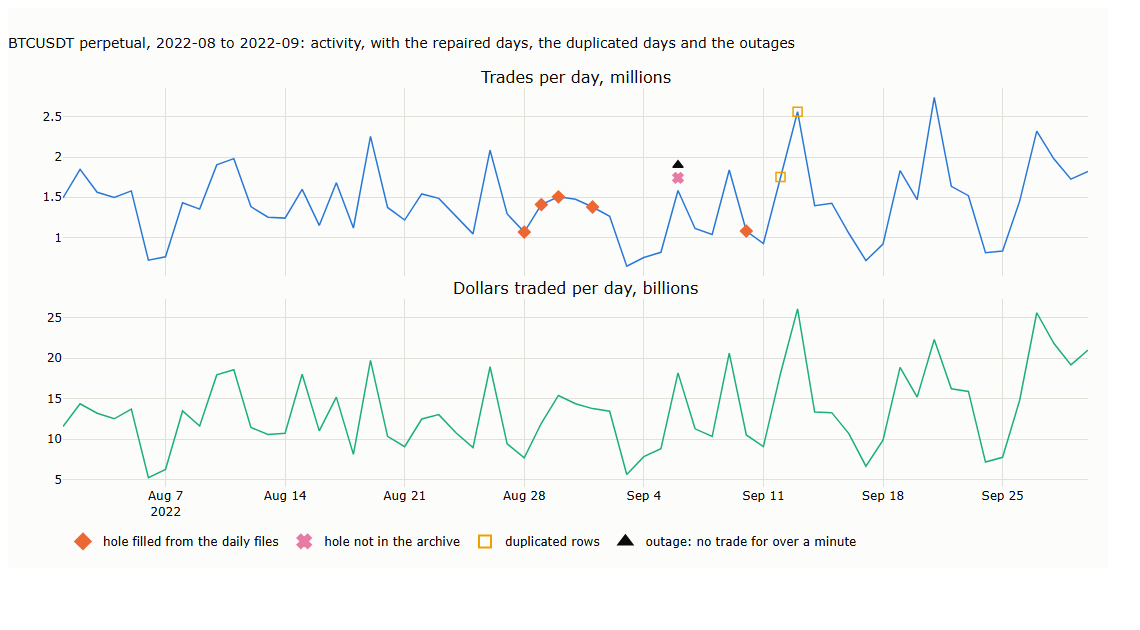

In [11]:
days = pl.concat([pl.read_parquet(D / ym / "days.parquet") for ym in period]).sort("day")
flags = pl.concat([pl.read_parquet(D / ym / "flag_counts.parquet") for ym in period])
marks = {"hole filled from the daily files": set(), "hole not in the archive": set(), "duplicated rows": set(), "outage: no trade for over a minute": set()}
for h in (patches.iter_rows(named=True) if patches.height else []):
    filled = h["status"] == "filled"
    marks["hole filled from the daily files" if filled else "hole not in the archive"].update(tape.hole_days(h["from_ms"], h["to_ms"], 60_000 if filled else 1))
for h in holes.filter(pl.col("kind") == "repeated").iter_rows(named=True):
    marks["duplicated rows"].add(datetime.fromtimestamp(h["from_ms"] / 1000, timezone.utc).date())
marks["outage: no trade for over a minute"] = {datetime.fromisoformat(d).date() for d in flags.filter(pl.col("rule") == "silence over 60 seconds")["day"]}

from plotly.subplots import make_subplots
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.06, subplot_titles=("Trades per day, millions", "Dollars traded per day, billions"))
fig.add_scatter(x=days["day"], y=days["trades"] / 1e6, mode="lines", line=dict(color=SERIES[0], width=1.5), showlegend=False, row=1, col=1)
fig.add_scatter(x=days["day"], y=days["usd"] / 1e9, mode="lines", line=dict(color=SERIES[2], width=1.5), showlegend=False, row=2, col=1)
style = {"hole filled from the daily files": ("diamond", SERIES[1], 1.00), "hole not in the archive": ("x", SERIES[3], 1.10),
         "duplicated rows": ("square-open", SERIES[4], 1.00), "outage: no trade for over a minute": ("triangle-up", INK, 1.20)}
for label, (sym, col, lift) in style.items():                              # marks on the trades line; lifted where two fall on one day
    q = days.filter(pl.col("day").is_in(sorted(marks[label])))
    fig.add_scatter(x=q["day"], y=q["trades"] / 1e6 * lift, mode="markers", marker=dict(symbol=sym, size=9, color=col, line=dict(width=1.5, color=col)),
                    name=label, row=1, col=1)
fig.update_layout(title=f"{SYMBOL} perpetual, {START} to {END}: activity, with the repaired days, the duplicated days and the outages", height=560, width=1100,
                  margin=dict(t=80), legend=dict(orientation="h", y=-0.1, x=0, itemsizing="constant"))
show(fig, "12_nb_coverage")

### 3.2 What to look at

The events of the map as a list: holes with their status, duplicated days, outages, and the days with the most unusual prints (§5.3).

In [12]:
ev = []
for h in (patches.iter_rows(named=True) if patches.height else []):
    ev.append(dict(when=datetime.fromtimestamp(h["from_ms"] / 1000, timezone.utc).strftime("%Y-%m-%d %H:%M:%S"), what=f"missing trades: {h['status']}", size=f"{h['n']:,} trades"))
for h in holes.filter(pl.col("kind") == "repeated").iter_rows(named=True):
    ev.append(dict(when=datetime.fromtimestamp(h["from_ms"] / 1000, timezone.utc).strftime("%Y-%m-%d"), what="duplicated rows (kept once in the clean month)", size=f"{h['n']:,} rows"))
ex = pl.concat([pl.read_parquet(D / ym / "flag_examples.parquet") for ym in period if pl.read_parquet(D / ym / "flag_examples.parquet").height])
for r in ex.filter(pl.col("rule") == "silence over 60 seconds").iter_rows(named=True):
    ev.append(dict(when=datetime.fromtimestamp(r["ms"] / 1000, timezone.utc).strftime("%Y-%m-%d %H:%M:%S"), what="outage: first trade after a silence", size=f"{r['value']:.0f} seconds"))
for r in flags.filter(pl.col("rule").is_in(["spike and revert", "jump that persists"])).group_by("day").agg(pl.col("n").sum()).sort("n", descending=True).head(5).iter_rows(named=True):
    ev.append(dict(when=r["day"], what="unusual prints (reverting or persisting)", size=f"{r['n']} prints"))
pl.DataFrame(ev).sort("when")

when,what,size
str,str,str
"""2022-08-19""","""unusual prints (reverting or persisting)""","""22 prints"""
"""2022-08-26""","""unusual prints (reverting or persisting)""","""16 prints"""
"""2022-08-27 23:59:59""","""missing trades: filled""","""3,977,571 trades"""
"""2022-08-31 23:59:59""","""missing trades: filled""","""1,377,907 trades"""
"""2022-09-06""","""unusual prints (reverting or persisting)""","""28 prints"""
"""2022-09-06 17:14:36""","""missing trades: not in the archive""","""31,645 trades"""
"""2022-09-06 17:20:57""","""outage: first trade after a silence""","""381 seconds"""
"""2022-09-06 17:58:09""","""missing trades: not in the archive""","""11 trades"""
"""2022-09-09 23:59:59""","""missing trades: filled""","""1,078,468 trades"""


### 3.3 Day view

Every trade of `DAY` (or of `WINDOW` within it), drawn as the event charts of the lecture (§5.4): coloured by the aggressor's side, large trades as bubbles,
flagged prints ringed, holes shaded, and cumulative net buying below.
A whole day holds one to nine million trades: the chart shows a thinned set chosen to keep the shape of the path,
and with `INTERACTIVE = True` it fetches the full detail of whatever range you zoom into.

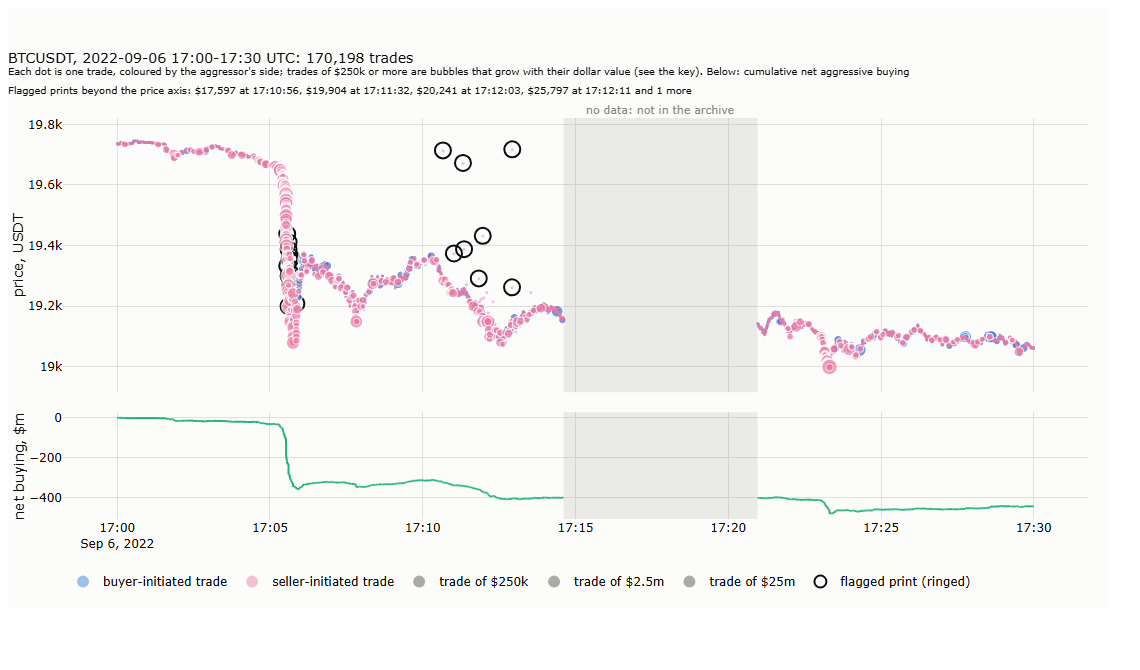

In [13]:
from plotly_resampler import FigureResampler

a, b = ms(f"{DAY} 00:00"), ms(f"{DAY} 00:00") + 86_400_000
if WINDOW:
    a, b = ms(f"{DAY} {WINDOW[0]}"), ms(f"{DAY} {WINDOW[1]}")
t = (pl.scan_parquet(tape.source(SYMBOL, DAY[:7])).filter(pl.col("transact_time").is_between(a, b, closed="left"))
       .select("transact_time", "price", "quantity", "is_buyer_maker").collect().with_columns(pl.from_epoch("transact_time", time_unit="ms").alias("time")))
from plotly.subplots import make_subplots
t = t.with_columns((pl.col("price") * pl.col("quantity")).alias("usd"), pl.when(pl.col("is_buyer_maker")).then(-1).otherwise(1).alias("sign"))
y_lo, y_hi = (float(t["price"].quantile(0.0005)), float(t["price"].quantile(0.9995))) if t.height else (0.0, 1.0)
pad = (y_hi - y_lo) * 0.1 + 1e-9; y_lo, y_hi = y_lo - pad, y_hi + pad          # the axis covers the bulk of the trades
f = ex.filter(pl.col("ms").is_between(a, b) & pl.col("rule").is_in(["spike and revert", "jump that persists"]))
beyond = f.filter((pl.col("price") > y_hi) | (pl.col("price") < y_lo))
BIG = 250_000
def bubble(usd):                                                           # as in the lecture's event charts: $250k 6 px, x10 adds 7 px
    return np.clip(6 + 7 * np.log10(np.maximum(usd, BIG) / BIG), 6, 30)
fig = FigureResampler(make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.72, 0.28], vertical_spacing=0.05),
                      default_n_shown_samples=3000, show_mean_aggregation_size=False, resampled_trace_prefix_suffix=("", ""))
for s_, col, nm in ((1, SERIES[0], "buyer-initiated trade"), (-1, SERIES[3], "seller-initiated trade")):
    q = t.filter(pl.col("sign") == s_)
    fig.add_trace(go.Scattergl(mode="markers", name=nm, marker=dict(size=3, color=col, opacity=0.45, line=dict(width=0))), hf_x=q["time"].to_numpy(), hf_y=q["price"].to_numpy(), row=1, col=1)
    big = q.filter(pl.col("usd") >= BIG)
    fig.add_trace(go.Scattergl(x=big["time"], y=big["price"], mode="markers", showlegend=False, marker=dict(size=bubble(big["usd"].to_numpy()), color=col, opacity=0.7, line=dict(width=1, color="white"))), row=1, col=1)
for v, lab in ((BIG, "$250k"), (2.5e6, "$2.5m"), (2.5e7, "$25m")):          # size key: points outside the plot, only for the legend
    fig.add_trace(go.Scattergl(x=[None], y=[None], mode="markers", name=f"trade of {lab}", marker=dict(size=bubble(np.array([v]))[0], color=MUTED, opacity=0.7)), row=1, col=1)
inside = f.filter((pl.col("price") <= y_hi) & (pl.col("price") >= y_lo))
fig.add_trace(go.Scatter(x=pl.from_epoch(inside["ms"], time_unit="ms"), y=inside["price"], mode="markers", name="flagged print (ringed)",
                         marker=dict(size=16, color=INK, symbol="circle-open", line=dict(width=2))), row=1, col=1)
fig.add_trace(go.Scattergl(mode="lines", line=dict(color=SERIES[2], width=2), showlegend=False), hf_x=t["time"].to_numpy(), hf_y=(t["usd"] * t["sign"]).cum_sum().to_numpy() / 1e6, row=2, col=1)
for h in (patches.iter_rows(named=True) if patches.height else []):
    lo_, hi_ = max(h["from_ms"], a), min(h["to_ms"], b)
    if lo_ < hi_:
        fig.add_vrect(x0=datetime.fromtimestamp(lo_ / 1000, timezone.utc), x1=datetime.fromtimestamp(hi_ / 1000, timezone.utc), fillcolor=MUTED, opacity=0.15, line_width=0, row="all", col=1)
        fig.add_annotation(x=datetime.fromtimestamp((lo_ + hi_) / 2000, timezone.utc), y=1, yref="y domain", text=f"no data: {h['status']}", showarrow=False,
                           yanchor="bottom", font=dict(size=11, color=MUTED))
note = ("<br><sup>Flagged prints beyond the price axis: " + ", ".join(f"${p:,.0f} at {datetime.fromtimestamp(m / 1000, timezone.utc):%H:%M:%S}" for p, m in zip(beyond["price"][:4], beyond["ms"][:4]))
        + (f" and {beyond.height - 4} more" if beyond.height > 4 else "") + "</sup>") if beyond.height else ""
fig.update_yaxes(title_text="price, USDT", range=[y_lo, y_hi], row=1, col=1); fig.update_yaxes(title_text="net buying, $m", row=2, col=1)
fig.update_layout(title=f"{SYMBOL}, {DAY} {'%s-%s UTC' % WINDOW if WINDOW else 'whole day'}: {t.height:,} trades<br><sup>Each dot is one trade, coloured by the aggressor's side; "
                        f"trades of $250k or more are bubbles that grow with their dollar value (see the key). Below: cumulative net aggressive buying</sup>{note}",
                  height=600, width=1100, margin=dict(t=110), legend=dict(orientation="h", y=-0.12, x=0, itemsizing="constant"))
if INTERACTIVE:
    fig.show_dash(mode="inline")
else:
    show(fig, "12_nb_day")

### 3.4 Density

Millions of trades cannot be drawn as points. **Datashader** counts them into the pixels of an image instead: each pixel's shade is the dollars
traded at that time and price. The span is processed one day at a time and the day images are added, which is exact, because a sum can be
computed in chunks (Appendix A.1). The price axis spans the range of the one-minute closes, so isolated prints far outside it are not drawn.
The default, the afternoon and evening of the Fed decision of 21 September 2022, shows where the dollars traded as the price swung (§8.6).

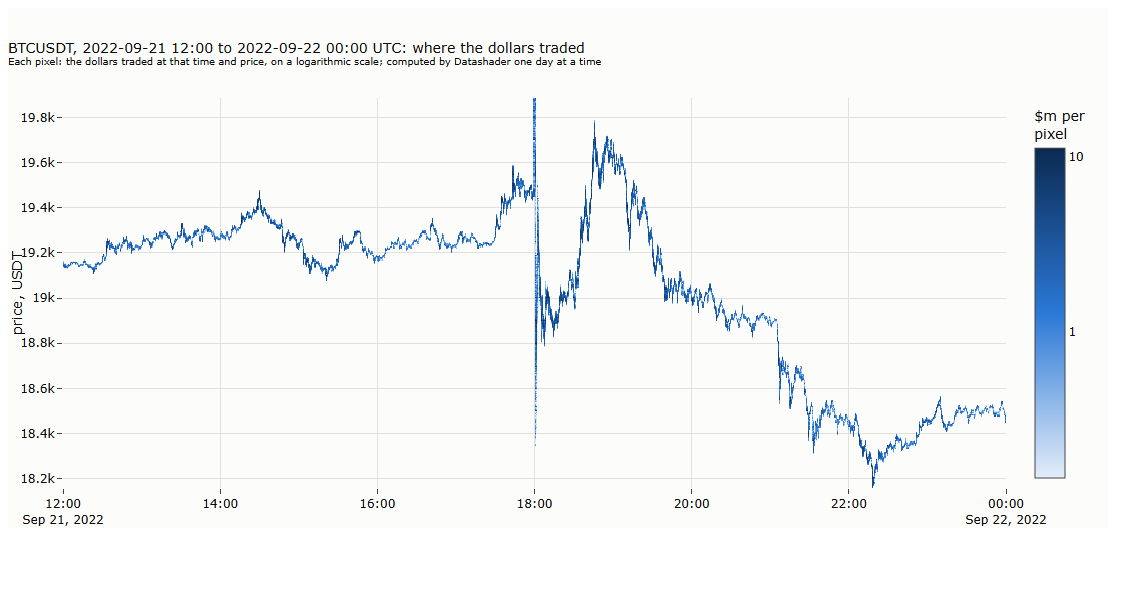

In [14]:
import datashader as ds

a, b = ms(DENSITY[0]), ms(DENSITY[1])
spans = sorted({datetime.fromtimestamp(x / 1000, timezone.utc).strftime("%Y-%m") for x in (a, b - 1)})
m1 = pl.concat([pl.read_parquet(D / ym / "m1.parquet", columns=["time", "close"]) for ym in spans]).filter(
    pl.col("time").is_between(datetime.fromtimestamp(a / 1000), datetime.fromtimestamp(b / 1000)))
lo, hi = float(m1["close"].min()) * 0.998, float(m1["close"].max()) * 1.002
canvas = ds.Canvas(plot_width=900, plot_height=360, x_range=(a, b), y_range=(lo, hi))
lf = pl.scan_parquet([tape.source(SYMBOL, ym) for ym in spans]).select("transact_time", "price", "quantity")
agg = None
for d0 in range(a, b, 86_400_000):                                     # one day at a time: bounded memory
    day = (lf.filter(pl.col("transact_time").is_between(d0, min(d0 + 86_400_000, b), closed="left"))
             .select(pl.col("transact_time").cast(pl.Float64), "price", (pl.col("price") * pl.col("quantity")).alias("usd")).collect().to_pandas())
    if len(day):
        part = canvas.points(day, "transact_time", "price", agg=ds.sum("usd"))
        part = part.fillna(0)                                          # empty pixels are NaN in Datashader: count them as zero dollars
        agg = part if agg is None else agg + part
z = np.log10(agg.values / 1e6, where=agg.values > 0, out=np.full(agg.shape, np.nan))   # millions of dollars per pixel, on a log scale
x = [datetime.fromtimestamp(v / 1000, timezone.utc).replace(tzinfo=None) for v in agg.coords["transact_time"].values]
fig = go.Figure(go.Heatmap(x=x, y=agg.coords["price"].values.tolist(), z=[[None if np.isnan(v) else round(float(v), 3) for v in row] for row in z],   # plain lists: portable HTML
                            colorscale=[[0, "#e3edf9"], [0.5, "#2a78d6"], [1, "#0b2a52"]], zmin=float(np.nanquantile(z, 0.05)), zmax=float(np.nanquantile(z, 0.995)),   # contrast: the bulk of the pixels
                           colorbar=dict(title="$m per<br>pixel", tickvals=[-2, -1, 0, 1, 2], ticktext=["0.01", "0.1", "1", "10", "100"]),
                           hovertemplate="%{x}<br>%{y:,.0f} USDT<extra></extra>"))
fig.update_yaxes(title_text="price, USDT")
fig.update_layout(title=f"{SYMBOL}, {DENSITY[0]} to {DENSITY[1]} UTC: where the dollars traded<br><sup>Each pixel: the dollars traded at that time and price, on a logarithmic scale; computed by Datashader one day at a time</sup>", height=520, width=1100, margin=dict(t=90))
show(fig, "12_nb_density")

### 3.5 Raw rows

The rows of the tape around `ROWS_AT`: the trade's ID, its time, price, size and side, how many single fills it combines, and the gap in IDs
and in time to the row before. A jump in `id_gap` is a missing trade; a jump in `ms_gap` is a silence.

In [15]:
def rows_around(when, n=8):
    t0 = ms(when)
    w = (pl.scan_parquet(tape.source(SYMBOL, when[:7])).filter(pl.col("transact_time").is_between(t0 - 600_000, t0 + 600_000)).collect().sort("agg_trade_id")
           .with_columns(pl.from_epoch("transact_time", time_unit="ms").alias("time"), (pl.col("price") * pl.col("quantity")).round(0).alias("usd"),
                         pl.when(pl.col("is_buyer_maker")).then(pl.lit("sell")).otherwise(pl.lit("buy")).alias("aggressor"),
                         (pl.col("last_trade_id") - pl.col("first_trade_id") + 1).alias("fills"),
                         pl.col("agg_trade_id").diff().alias("id_gap"), pl.col("transact_time").diff().alias("ms_gap")))
    i = int(np.argmin(np.abs(w["transact_time"].to_numpy() - t0)))
    return w.slice(max(i - n, 0), 2 * n + 1).select("agg_trade_id", "time", "price", "quantity", "usd", "aggressor", "fills", "id_gap", "ms_gap")

rows_around(ROWS_AT)

agg_trade_id,time,price,quantity,usd,aggressor,fills,id_gap,ms_gap
i64,datetime[μs],f64,f64,f64,str,i64,i64,i64
1439638952,2022-09-06 17:12:26.328,19113.5,0.051,975.0,"""buy""",1,1,1
1439638953,2022-09-06 17:12:26.328,19112.5,0.204,3899.0,"""sell""",3,1,0
1439638954,2022-09-06 17:12:26.338,19113.5,0.281,5371.0,"""buy""",3,1,10
1439638955,2022-09-06 17:12:26.341,19112.4,0.049,937.0,"""sell""",4,1,3
1439638956,2022-09-06 17:12:26.358,19113.3,0.001,19.0,"""buy""",1,1,17
1439638957,2022-09-06 17:12:26.358,19113.5,0.049,937.0,"""buy""",1,1,0
1439638958,2022-09-06 17:12:26.359,19112.4,0.574,10971.0,"""sell""",3,1,1
1439638959,2022-09-06 17:12:26.370,19112.8,0.794,15176.0,"""buy""",4,1,11
1439638960,2022-09-06 17:12:26.397,19112.4,0.173,3306.0,"""sell""",3,1,27


### 3.6 The extreme events of the period

The largest persisting jump, the largest reverting spike, the largest single trade and the busiest minute of the period, each tested and drawn
as in §5.4 of the lecture: every trade as a dot coloured by the aggressor's side, trades of $250k or more as bubbles, cumulative net buying below.

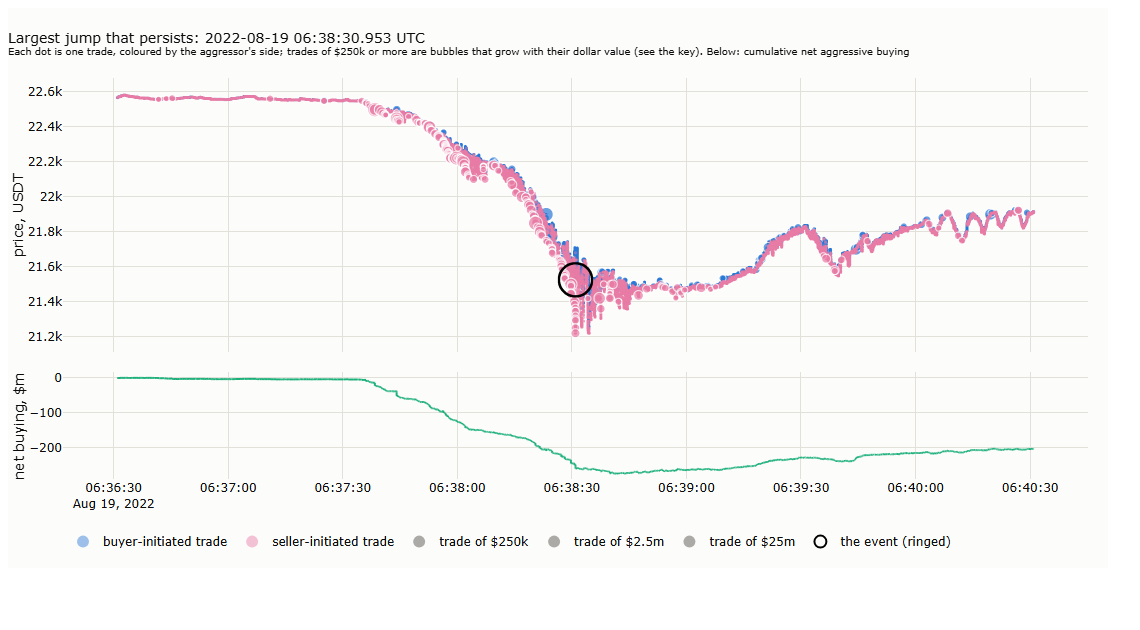

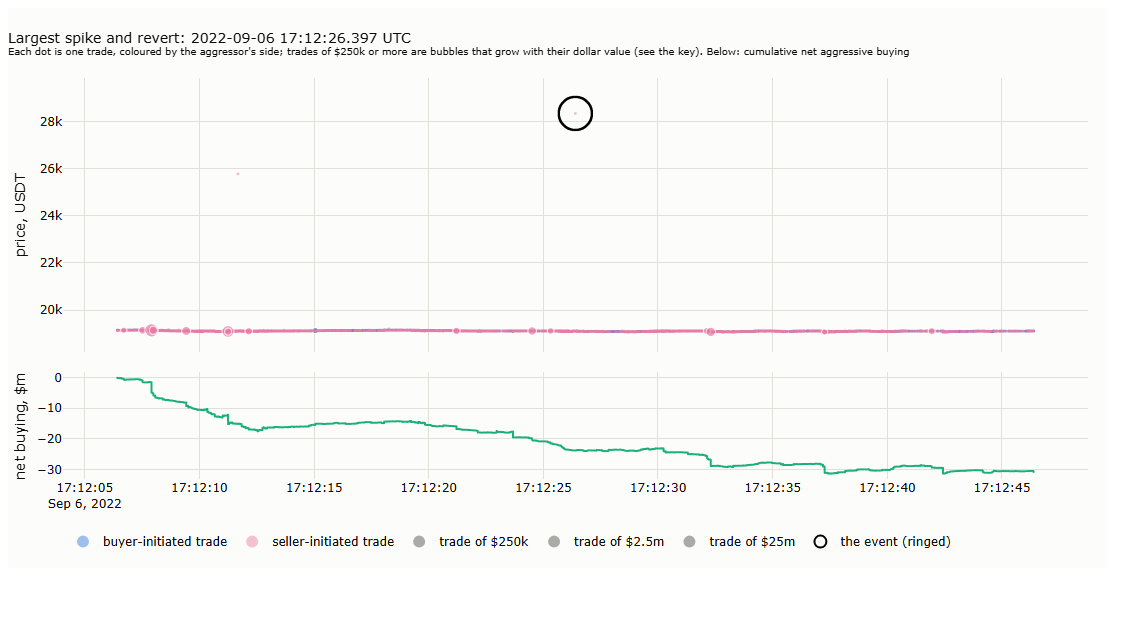

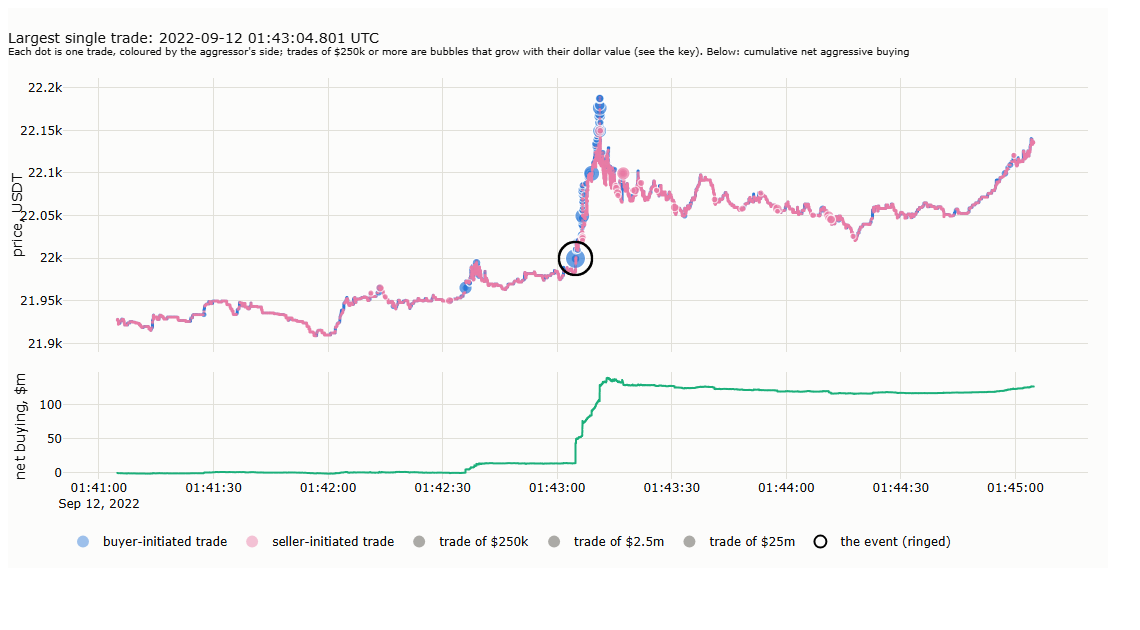

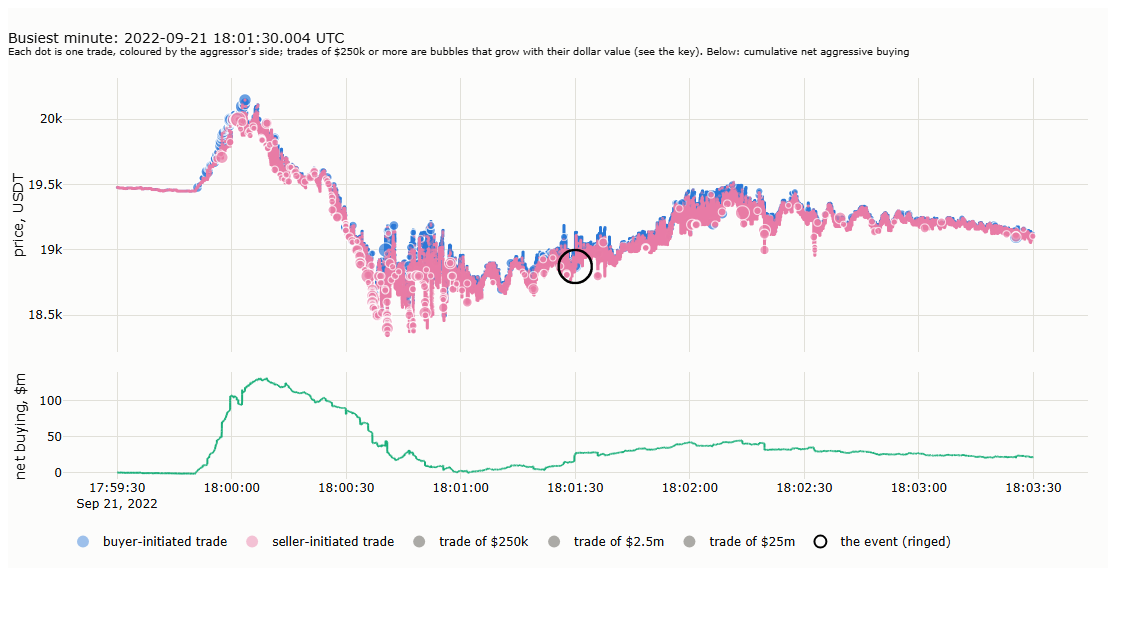

measure,value
str,str
"""largest jump that persists / when""","""2022-08-19 06:38:30.953 UTC"""
"""largest jump that persists / price""","""2.153e+04"""
"""largest jump that persists / size_usd""","""86.1"""
"""largest jump that persists / jump_bp""","""142.4"""
"""largest jump that persists / kept_after_10_trades""","""1.418"""
"""largest jump that persists / kept_after_60s""","""1.989"""
"""largest jump that persists / levels_between""","""3023"""
"""largest jump that persists / share_levels_traded""","""0.008601"""
"""largest jump that persists / largest_step_bp""","""72.33"""


In [16]:
import l12_figures as F

def as_table(d, prefix=""):
    """A nested dictionary of results as a two-column table."""
    rows = []
    for k, v in (d or {}).items():
        if isinstance(v, dict):
            rows += as_table(v, f"{prefix}{k} / ").rows()
        else:
            rows.append((f"{prefix}{k}", f"{v:,.4g}" if isinstance(v, float) else str(v)))
    return pl.DataFrame(rows, schema=["measure", "value"], orient="row")

def pictures(*names):
    for nm in names:
        display(Image(filename=str(FIG / f"nb_{nm}.png")))

events = F.run_events(SYMBOL, period, FIG)
pictures("12_02_event_largest_jump_that_persists", "12_03_event_largest_spike_and_revert", "12_04_event_largest_single_trade", "12_05_event_busiest_minute")
as_table(events)

## 4. The market's activity

§6 of the lecture. The cells below run the code that made the lecture's figures, on the period chosen in §0: on October 2021 to
September 2026 they redraw the lecture's figures; on another period they draw the same figures for that period. The charts are saved under
`figures/` with names starting `nb_`, so the lecture's own figures are never overwritten.

### 4.1 Trade sizes, the aggressor, the time of day, the time between trades

Lecture §6.1-§6.5: one function computes all four, and the signature plot of §5.2 below.

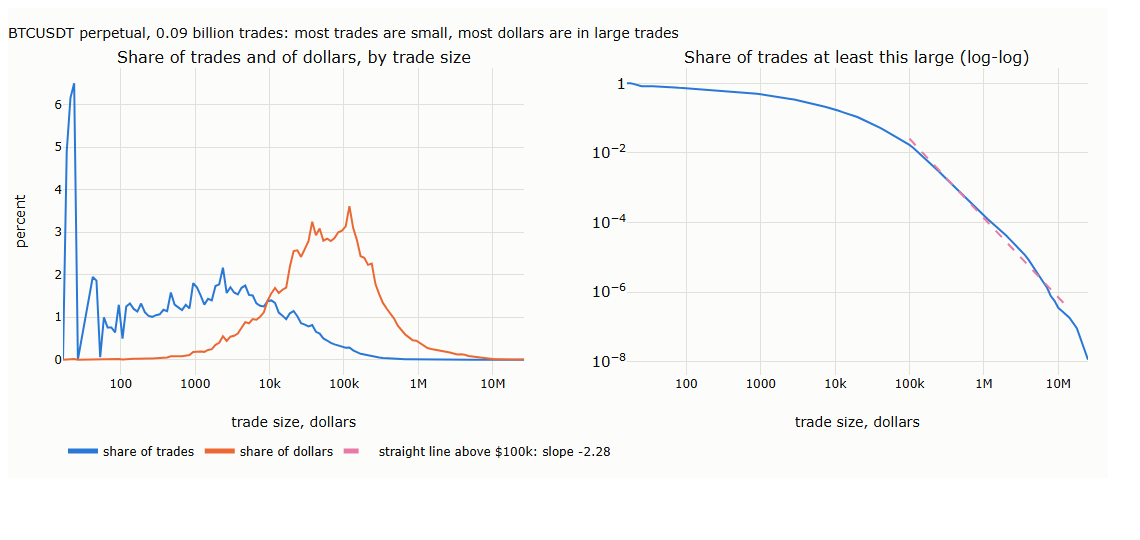

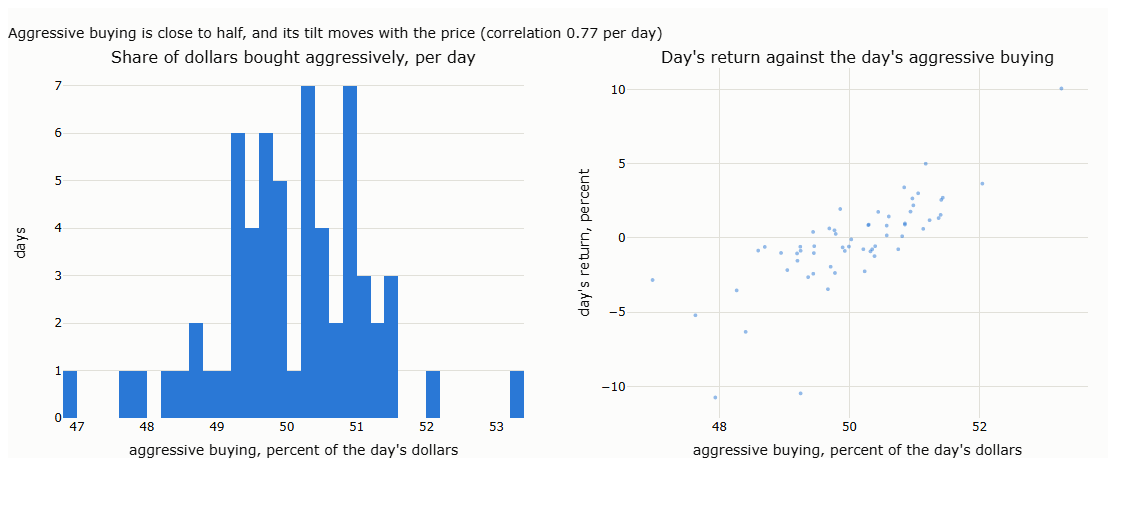

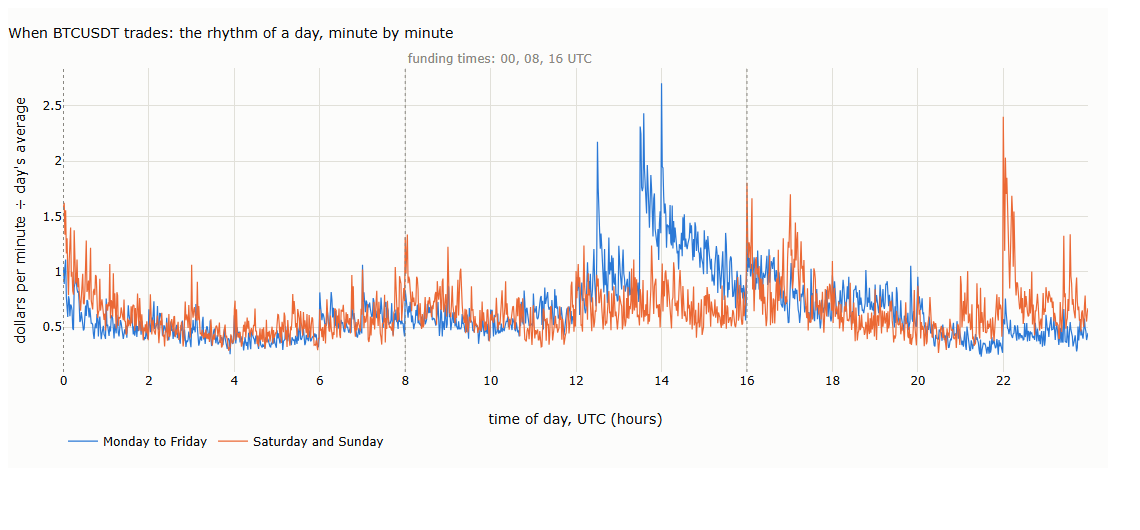

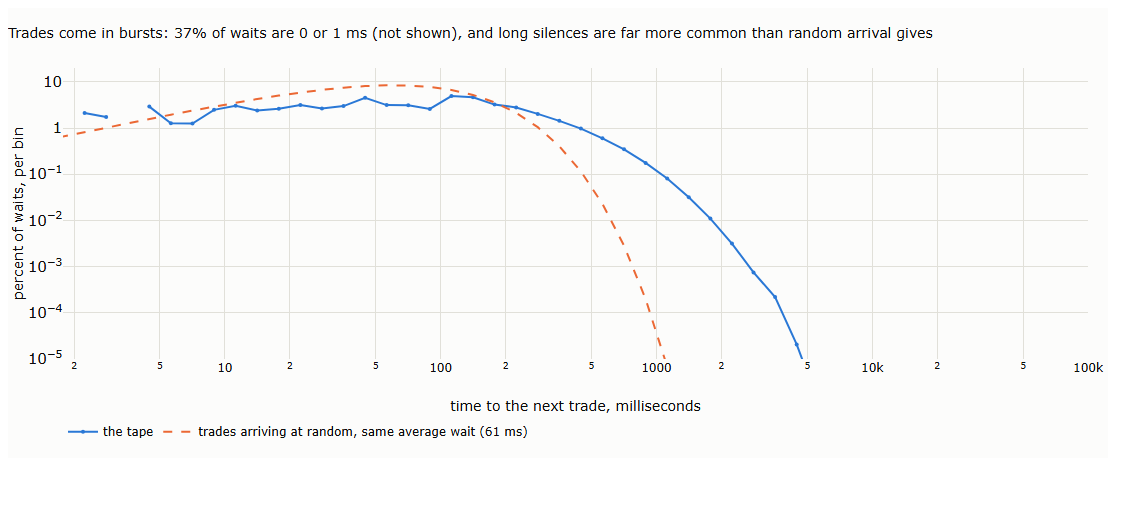

measure,value
str,str
"""sizes / trades""","""86896965"""
"""sizes / tail_exponent""","""2.279"""
"""sizes / top1""","""0.2793"""
"""sizes / top10""","""0.7441"""
"""sizes / share_trades_under_1000""","""0.5124"""
"""sizes / share_usd_over_1m""","""0.03153"""
"""aggressor / buy_share_mean""","""0.5006"""
"""aggressor / buy_share_p05""","""0.4827"""
"""aggressor / buy_share_p95""","""0.5142"""


In [17]:
stats6 = F.run_activity_stats(SYMBOL, period, FIG)
pictures("12_06_trade_sizes", "12_07_aggressor", "12_08_time_of_day", "12_09_durations")
as_table({k: v for k, v in stats6.items() if k in ("sizes", "aggressor", "time_of_day", "durations")})

### 4.2 Around the funding times

Activity, volatility and price an hour either side of each funding payment, by funding rate (lecture §6.2). The funding history is downloaded once from the archive.

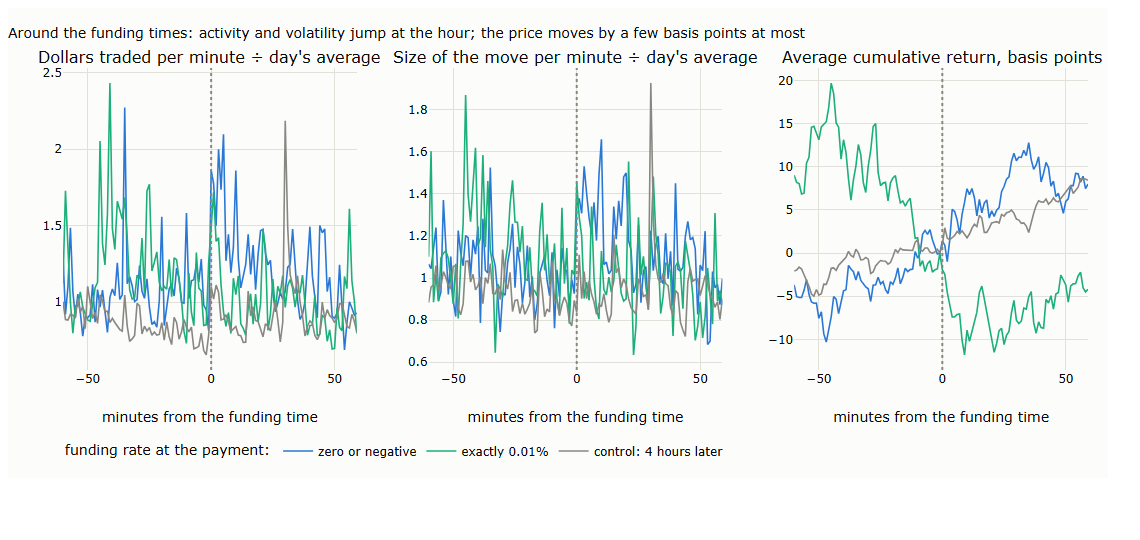

measure,value
str,str
"""control: 4 hours later / before30_bp""","""0.502"""
"""control: 4 hours later / before30_se""","""2.415"""
"""control: 4 hours later / events""","""183"""
"""control: 4 hours later / after30_bp""","""4.632"""
"""control: 4 hours later / after30_se""","""2.237"""
"""control: 4 hours later / before5_bp""","""-0.594"""
"""control: 4 hours later / before5_se""","""0.953"""
"""control: 4 hours later / after5_bp""","""1.849"""
"""control: 4 hours later / after5_se""","""1.168"""


In [18]:
fund = F.run_funding(SYMBOL, period, FIG)
pictures("12_17_funding_event")
as_table(fund)

## 5. How prices form

§7 of the lecture: whether order flow follows itself, how much noise trading adds to measured volatility, and what lies behind large moves.

### 5.1 Persistence of order flow

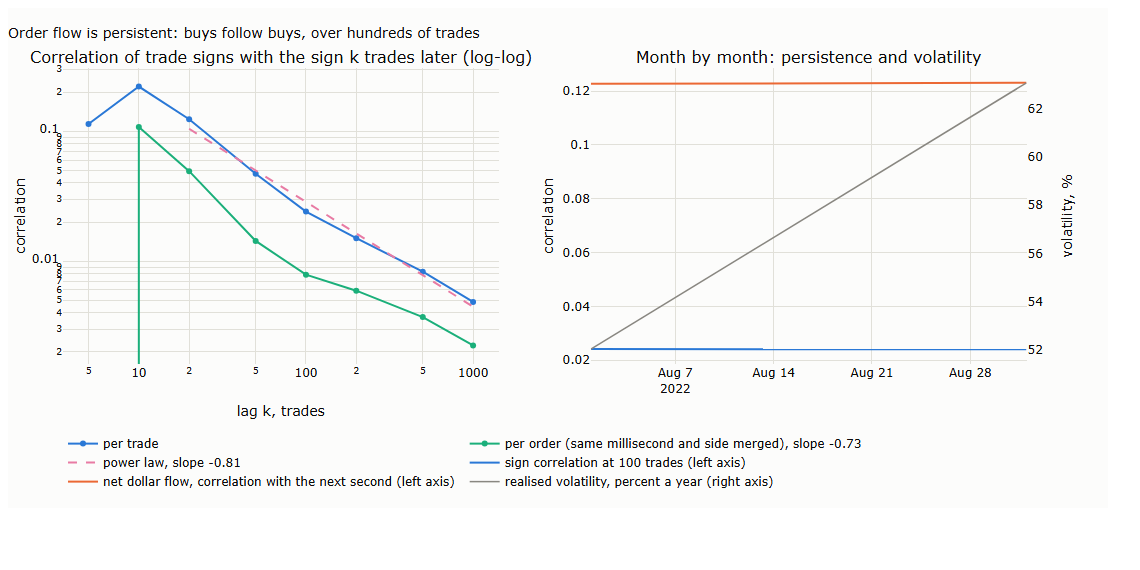

measure,value
str,str
"""sign_acf_trade / 1""","""0.0109"""
"""sign_acf_trade / 2""","""0.5058"""
"""sign_acf_trade / 5""","""0.1137"""
"""sign_acf_trade / 10""","""0.2211"""
"""sign_acf_trade / 20""","""0.1238"""
"""sign_acf_trade / 50""","""0.0471"""
"""sign_acf_trade / 100""","""0.0241"""
"""sign_acf_trade / 200""","""0.015"""
"""sign_acf_trade / 500""","""0.0083"""


In [19]:
pers = F.run_persistence(SYMBOL, period, FIG)
pictures("12_11_flow_persistence")
as_table({k: v for k, v in pers.items() if k in ("sign_acf_trade", "sign_acf_order", "decay_exponent_trade", "decay_exponent_order", "flow_acf_1s", "ret_acf_1s")})

### 5.2 The signature plot

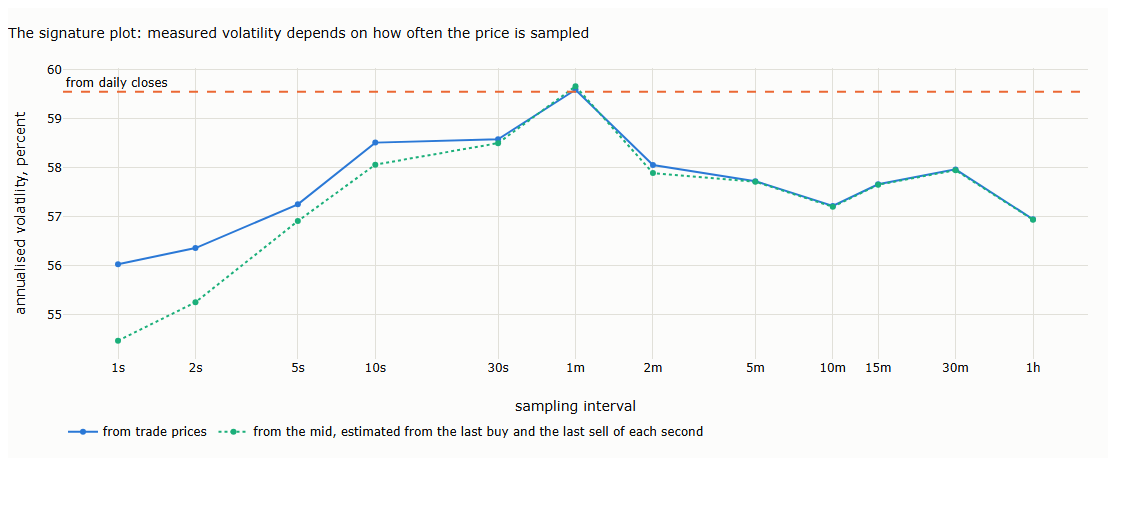

measure,value
str,str
"""ac1_trade_median""","""-0.4808"""
"""ac1_1s_median""","""0.008838"""
"""vol_by_interval / 1""","""0.5604"""
"""vol_by_interval / 2""","""0.5636"""
"""vol_by_interval / 5""","""0.5725"""
"""vol_by_interval / 10""","""0.5851"""
"""vol_by_interval / 30""","""0.5858"""
"""vol_by_interval / 60""","""0.5959"""
"""vol_by_interval / 120""","""0.5806"""


In [20]:
pictures("12_10_signature")
as_table(stats6.get("bounce"))

### 5.3 What drives large moves

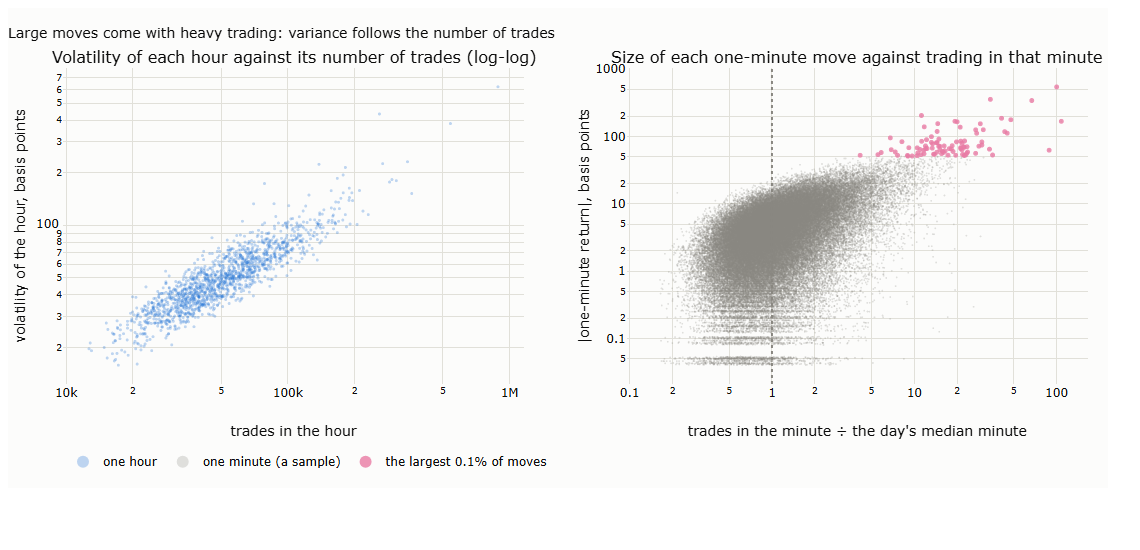

measure,value
str,str
"""hourly / hours""","""1464"""
"""hourly / trades / coef / trades""","""1.42"""
"""hourly / trades / r2""","""0.8101"""
"""hourly / size / coef / size""","""2.418"""
"""hourly / size / r2""","""0.3035"""
"""hourly / usd / coef / usd""","""1.155"""
"""hourly / usd / r2""","""0.8037"""
"""hourly / trades_and_size / coef / trades""","""1.324"""
"""hourly / trades_and_size / coef / size""","""0.5162"""


In [21]:
large = F.run_large_moves(SYMBOL, period, FIG)
pictures("12_12_large_moves")
as_table(large)

## 6. What a candle loses

§8 of the lecture: the same candle with different flow, order flow and volatility estimated from candles, the close against the average
price, and volume by price on one day.

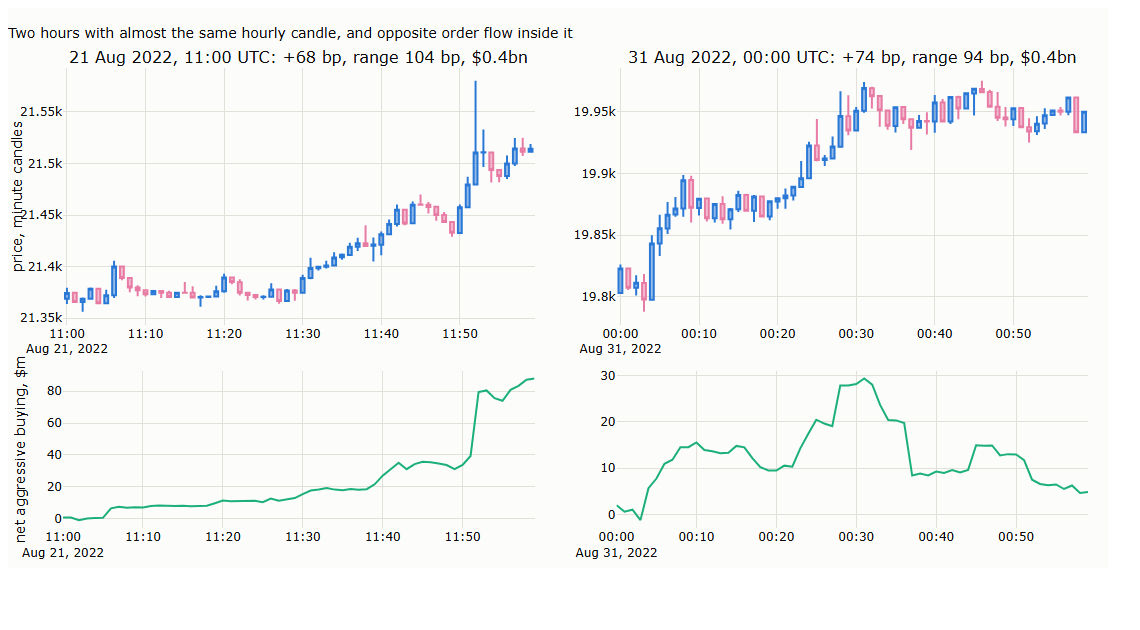

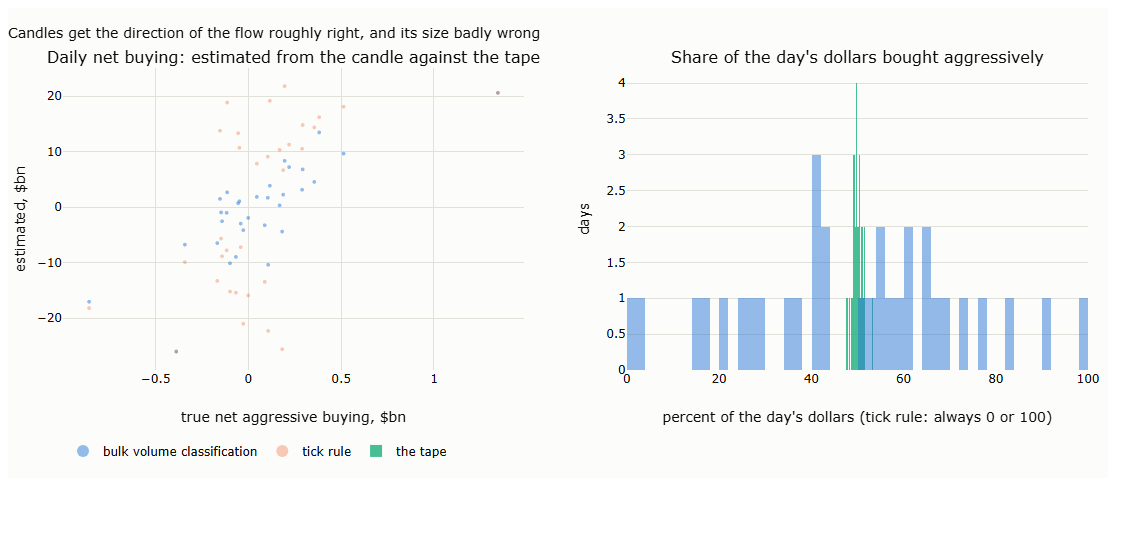

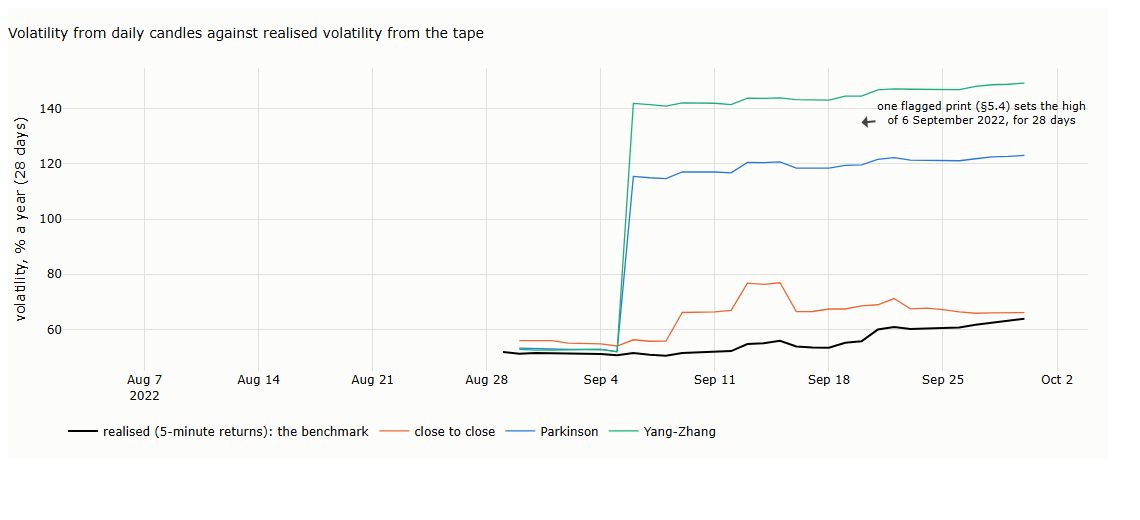

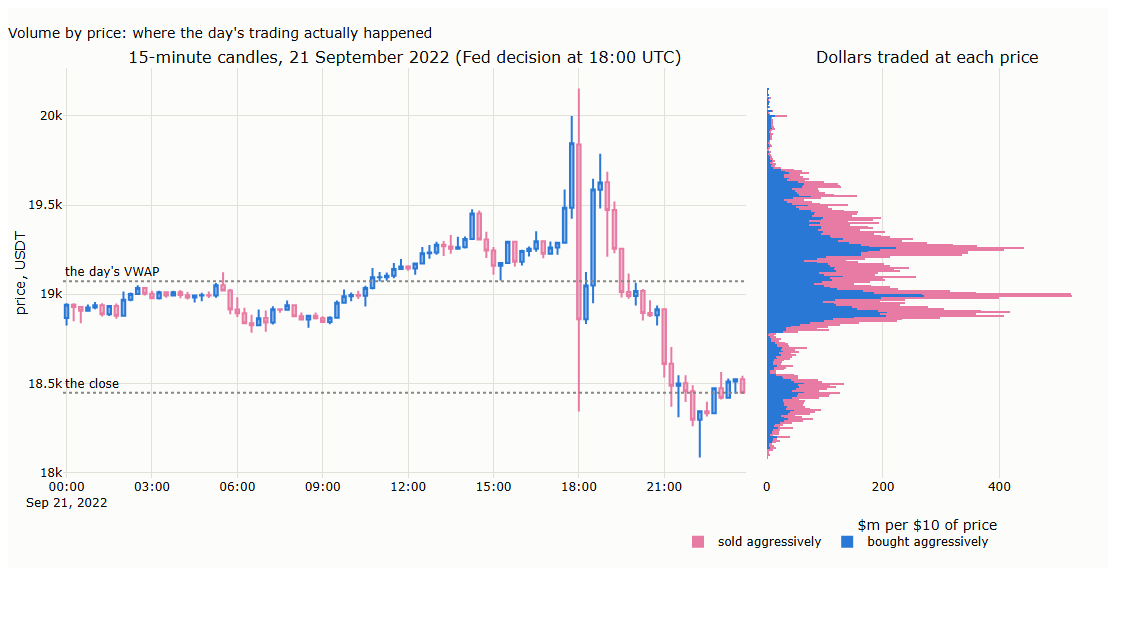

measure,value
str,str
"""flow / 1m / bars""","""86394"""
"""flow / 1m / corr_tick""","""0.7761"""
"""flow / 1m / corr_bvc""","""0.8255"""
"""flow / 1m / sign_right_tick""","""0.7794"""
"""flow / 1m / sign_right_bvc""","""0.7794"""
"""flow / 1m / buy_share_err_tick""","""0.4014"""
"""flow / 1m / buy_share_err_bvc""","""0.1304"""
"""flow / 1m / true_imbalance_abs_median""","""0.2222"""
"""flow / 1m / bvc_imbalance_abs_median""","""0.3795"""


In [22]:
PROFILE_DAY = "2022-09-21"      # CHANGE HERE: the day of the volume profile (§8.6); the default is the Fed decision of 21 September 2022
if PROFILE_DAY[:7] not in period:
    PROFILE_DAY = f"{period[0]}-15"; print(f"PROFILE_DAY is outside the period: showing {PROFILE_DAY} instead")
cand = F.run_candles(SYMBOL, period, FIG, PROFILE_DAY=PROFILE_DAY)
pictures("12_15_same_candle", "12_13_flow_from_candles", "12_14_range_estimators", "12_16_volume_profile")
as_table(cand)